# Historical raw-label comparison — superseded by notebook 06

**Correction, 21 October 2026:** this historical analysis pools the bare species
label `s__` for 20 unresolved genomes across six genera. That does not establish
conspecificity. Its species-control inference is superseded by notebook 06, which
excludes unresolved assignments and refits the comparisons. Inputs and original
estimates below remain for audit; they are not the current primary conclusions.

This is an exploratory reanalysis of published bacterial data addressing the
ecology/evolution question. It complements the archaeome study in notebook 04.
It is **not replication of temperature-associated encrypted APEX fragments**:
Du et al. used Macrel on small ORFs, a distinct endpoint. These are predicted
candidate counts, not measured antimicrobial function or potency.

[Original article and supplementary tables](https://doi.org/10.1186/s40168-025-02145-3)
are CC BY 4.0. All original tables, source hashes, exact joins, zero-hit genomes
and derived analysis data are retained. The analysis addendum (07a490c) was
committed after seeing the archaeome pilot but before this comparison's fits.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
from IPython.display import display
from genomespot_lens.ecology_comparison import fit_count_contrasts, within_species_permutation
get_ipython().run_line_magic('matplotlib','inline')
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/genomespot_lens').exists())
DATA=ROOT/'examples/lactobacillaceae-ecology'
genomes=pd.read_csv(DATA/'genomes.csv')
hits=pd.read_csv(DATA/'hit-registry.csv')
provenance=json.loads((DATA/'provenance.json').read_text())
assert provenance['data_kind']=='real'
assert genomes.genome_id.is_unique and hits.hit_id.is_unique
assert set(hits.genome_id).issubset(genomes.genome_id)
assert genomes.amp_count.sum()==len(hits)==1327
assert genomes.amp_count.eq(0).sum()==1084
FIG=ROOT/'study/ecology-comparison/figures';FIG.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
def save(fig,name):
    for fmt in ['png','svg']:fig.savefig(FIG/f'{name}.{fmt}',dpi=180,bbox_inches='tight')
display(pd.Series({k:provenance[k] for k in ['genomes','positive_genomes','zero_genomes',
    'species','multi_habitat_species','common_support_genomes','informative_common_support_species',
    'informative_common_support_genomes']}))

genomes                               1964
positive_genomes                       880
zero_genomes                          1084
species                                137
multi_habitat_species                   40
common_support_genomes                1323
informative_common_support_species      36
informative_common_support_genomes    1312
dtype: int64

## Exact source and zero accounting

The original MAG registry enumerates every screened genome, including no-hit
members. S4 and S5 contain the same 1,327 positive records with identical fields;
the preparation runner verifies that identity and all genome/species/habitat
joins. A missing hit becomes zero only inside this screened registry. We do not
assume that an unlisted genome was screened.

Genome quality, size and GC are available; the number of small ORFs screened per
genome is absent. Genome size is therefore an estimated covariate, not an exact
screening offset. Niche is associated with source dataset as well as biology;
these observational tables cannot separate all source-study effects.

,habitat,genomes,species,candidates,positive_genomes,mean_genome_bp,mean_completeness,mean_contamination,candidates_per_genome
0,animal,1244,74,920,584,1.630315e+06,88.834871,2.476217,0.739550
1,fermented food,197,71,168,114,1.930886e+06,80.589797,2.951117,0.852792
2,human,523,42,239,182,1.584199e+06,80.656852,0.691764,0.456979


,contrast,shared_species,pair_genomes
0,human / animal,24,1123
1,fermented food / animal,17,230
2,fermented food / human,19,241


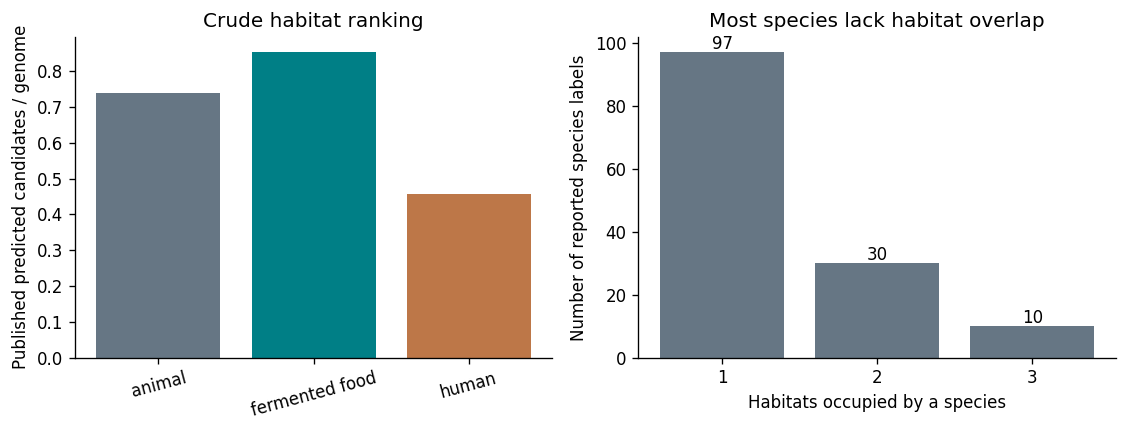

In [2]:
summary=pd.read_csv(DATA/'habitat-summary.csv')
display(summary)
overlap=pd.read_csv(DATA/'species-habitat-overlap.csv').set_index('species')
support=[]
for a,b in [('human','animal'),('fermented food','animal'),('fermented food','human')]:
    shared=overlap.index[(overlap[a]>0)&(overlap[b]>0)]
    support.append({'contrast':f'{a} / {b}','shared_species':len(shared),
        'pair_genomes':int((genomes.species.isin(shared)&genomes.habitat.isin([a,b])).sum())})
display(pd.DataFrame(support))
fig,axes=plt.subplots(1,2,figsize=(9.5,3.7))
colors=['#667684','#007f86','#bd7748']
axes[0].bar(summary.habitat,summary.candidates_per_genome,color=colors)
axes[0].set(ylabel='Published predicted candidates / genome',title='Crude habitat ranking')
axes[0].tick_params(axis='x',rotation=15)
number=(overlap>0).sum(axis=1).value_counts().sort_index()
axes[1].bar([str(n) for n in number.index],number.values,color='#667684')
axes[1].set(xlabel='Habitats occupied by a species',ylabel='Number of reported species labels',title='Most species lack habitat overlap')
for i,n in enumerate(number.values):axes[1].text(i,n+1,str(n),ha='center')
fig.tight_layout();save(fig,'habitat_and_species_coverage');plt.show()

## Compare the same genomes before and after species adjustment

Forty species span multiple habitats (1,323 genomes). Four all-zero species,
11 genomes, cannot inform conditional count contrasts. All three matched-cohort
models use the identical remaining **1,312 genomes / 36 species**; individual
zero-hit genomes remain. A full-cohort crude estimate uses all 1,964 genomes.

Poisson pseudo-maximum likelihood supplies a count mean model, with species
fixed effects where indicated. Species-cluster sandwich uncertainty, finite
sample correction and t intervals use 35 degrees of freedom in matched models.
The quality model also adds standardized log genome size, completeness,
contamination and GC. Species fixed effects control species-level differences,
not all fine-scale strain relatedness or cross-species ancestry. All three habitat contrasts and omnibus
F tests are reported. The intervals and p-values are exploratory, unadjusted
for multiple comparisons; no favorable contrast is selected for discovery.

In [3]:
matched=genomes[genomes.count_model_eligible].copy()
rerun=pd.concat([
    fit_count_contrasts(genomes,label='crude_all'),
    fit_count_contrasts(matched,label='crude_common_support'),
    fit_count_contrasts(matched,species_effect=True,label='species_common_support'),
    fit_count_contrasts(matched,species_effect=True,quality=True,label='species_quality_common_support')],ignore_index=True)
saved=pd.read_csv(DATA/'effects.csv')
assert rerun[['model','contrast']].equals(saved[['model','contrast']])
for name in ['rate_ratio','ci_low','ci_high','omnibus_habitat_p']:
    assert np.allclose(rerun[name],saved[name],rtol=1e-6,atol=1e-8)
display(rerun[['model','contrast','genomes','species_clusters','rate_ratio','ci_low','ci_high','p_value']])
display(rerun.drop_duplicates('model')[['model','omnibus_habitat_f','omnibus_habitat_p','pearson_dispersion','design_condition_number']])

,model,contrast,genomes,species_clusters,rate_ratio,ci_low,ci_high,p_value
0,crude_all,human / animal,1964,137,0.617915,0.363170,1.051350,0.075479
1,crude_all,fermented food / animal,1964,137,1.153123,0.749189,1.774843,0.514632
2,crude_all,fermented food / human,1964,137,1.866151,1.183401,2.942806,0.007624
3,crude_common_support,human / animal,1312,36,0.539826,0.280822,1.037711,0.063678
4,crude_common_support,fermented food / animal,1312,36,0.819216,0.482148,1.391929,0.450183
5,crude_common_support,fermented food / human,1312,36,1.517556,0.885592,2.600494,0.124913
6,species_common_support,human / animal,1312,36,0.752578,0.581203,0.974485,0.032031
7,species_common_support,fermented food / animal,1312,36,0.809893,0.584734,1.121751,0.197366
8,species_common_support,fermented food / human,1312,36,1.076158,0.799244,1.449014,0.619594
9,species_quality_common_support,human / animal,1312,36,0.745966,0.550641,1.010576,0.058025


,model,omnibus_habitat_f,omnibus_habitat_p,pearson_dispersion,design_condition_number
0,crude_all,3.675217,0.027894,1.245279,3.666666
3,crude_common_support,1.954473,0.156792,1.236465,4.011823
6,species_common_support,2.518822,0.095059,0.964272,56.598515
9,species_quality_common_support,2.450268,0.100940,0.902637,69.898558


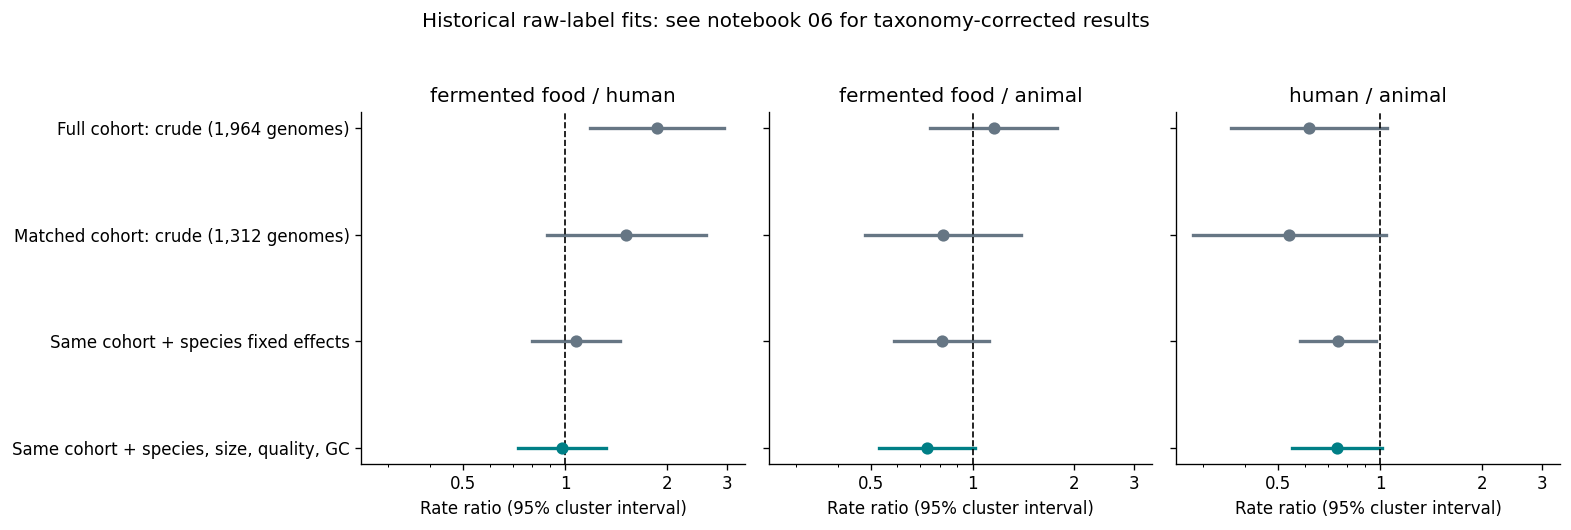

In [4]:
labels={'crude_all':'Full cohort: crude (1,964 genomes)',
        'crude_common_support':'Matched cohort: crude (1,312 genomes)',
        'species_common_support':'Same cohort + species fixed effects',
        'species_quality_common_support':'Same cohort + species, size, quality, GC'}
contrasts=['fermented food / human','fermented food / animal','human / animal']
fig,axes=plt.subplots(1,3,figsize=(13.2,4.2),sharey=True)
for j,(ax,contrast) in enumerate(zip(axes,contrasts)):
    subset=rerun[rerun.contrast==contrast].reset_index(drop=True)
    for i,r in subset.iterrows():
        color='#007f86' if r.quality_adjusted else '#667684'
        ax.plot([r.ci_low,r.ci_high],[i,i],color=color,lw=2)
        ax.scatter(r.rate_ratio,i,color=color,s=40,zorder=3)
    ax.axvline(1,color='black',lw=1,ls='--')
    ax.set_xscale('log');ax.set_xticks([.5,1,2,3],['0.5','1','2','3'])
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set(xlim=(.25,3.4),xlabel='Rate ratio (95% cluster interval)',title=contrast)
axes[0].set_yticks(range(4),list(labels.values()));axes[0].invert_yaxis()
fig.suptitle('Historical raw-label fits: see notebook 06 for taxonomy-corrected results',y=1.04)
fig.tight_layout();save(fig,'habitat_effects_species_controls');plt.show()

## Report the sensitivity that does not fully agree

A separate omnibus Poisson score test permutes habitat labels within the 40
multi-habitat species (9,999 permutations, seed 23). It holds species membership,
within-species habitat frequencies and candidate counts fixed. This tests an
unadjusted within-species association under exchangeability, not a quality-
adjusted causal effect. It can disagree with the species-cluster Wald/F inference;
we report both, rather than discard an inconvenient result.

In [5]:
permutation=within_species_permutation(genomes[genomes.multi_habitat_species],permutations=9999,seed=23)
stored_permutation=json.loads((DATA/'permutation.json').read_text())
display(pd.Series(permutation))
# BLAS architectures may round the quadratic score differently. Counts,
# exceedances and the Monte Carlo p-value must still reproduce exactly.
assert np.isclose(permutation['statistic'],stored_permutation['statistic'],rtol=1e-12,atol=1e-12)
assert {k:v for k,v in permutation.items() if k!='statistic'} == {k:v for k,v in stored_permutation.items() if k!='statistic'}

statistic                                                          6.06392
permutations                                                          9999
seed                                                                    23
exceedances                                                            413
p_value                                                             0.0414
genomes                                                               1323
species                                                                 40
multi_habitat_species                                                   40
quality_adjusted                                                     False
null_assumption          Habitat labels exchangeable within species; ob...
dtype: object

## What this supports

The fermented-food/human candidate-count ratio falls from **1.87** (95% interval
1.18–2.94) in the full cohort to **1.08** (0.80–1.45) with species fixed effects
and **0.98** (0.73–1.32) after genome covariates. The matched-cohort crude ratio is
1.52 (0.89–2.60), showing that cohort support also matters. These models estimate
different target populations; the change is not a causal decomposition.

The unadjusted permutation test has p=0.0414, while the quality-adjusted omnibus
cluster F test has p≈0.101. Thus ecology is **not ruled out**. The narrower supported
finding is that the crude fermented-food advantage is not robust in this analysis.
Genome assembly quality, small-ORF calling, source-study differences and strain
relatedness remain possible explanations. Counts do not establish peptide
expression, release, measured activity, ecological adaptation, or resistance
co-evolution. This dataset cannot answer the encrypted-AMP/AMR question.

Together with the archaeome pilot, this motivates a concrete direction: **which
ecological AMP associations survive ancestry, composition and screening
ascertainment controls?** Neither general AMP ecology nor statistical adjustment
is new; the proposed contribution is an auditable comparison using exact source
mapping and complete zero/denominator accounting. A full uniformly screened ATB
cohort and independent temperature replication are still required for stronger
claims. See `study/ecology-comparison/results.md` and the corrected extension in
`study/ecology-comparison/robustness-results-2026-10-21.md`.